# 🚀 Модуль 0. Урок 3. Аналитическое мышление и методология CRISP-DM в реальных проектах

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_00_onboarding/lesson_03_analytical_thinking_crisp_dm.ipynb)

## 📌 Бизнес-контекст и методология
Анализ данных без методологии превращается в хаотичное исследование таблиц.
Мировой индустриальный стандарт **CRISP-DM (Cross-Industry Standard Process for Data Mining)** описывает жизненный цикл аналитического проекта:
1. **Business Understanding:** понимание бизнес-цели и финансовых ограничений
2. **Data Understanding:** первичная разведка данных, оценка полноты
3. **Data Preparation:** очистка, валидация, создание витрин
4. **Modeling / Analysis:** расчет статистических тестов, сегментация
5. **Evaluation:** проверка гипотез и сопоставление с бизнес-целью
6. **Deployment:** внедрение в дашборды, презентация стейкхолдерам

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Итерационный цикл CRISP-DM
CRISP-DM — это не водопадная модель (waterfall), а **итеративный цикл**.
Если на этапе Evaluation выясняется, что модель не отвечает бизнес-требованиям, аналитик возвращается на этап Business или Data Understanding.

In [2]:
# Демонстрация: Оценка распределения ресурсов проекта по этапам CRISP-DM
crisp_phases = pd.DataFrame({
    'Фаза CRISP-DM': ['1. Business Understanding', '2. Data Understanding', '3. Data Preparation', '4. Modeling & Analytics', '5. Evaluation', '6. Deployment'],
    'Доля времени (%)': [15, 20, 35, 15, 10, 5],
    'Критический артефакт': ['Бизнес-бриф и метрики успеха', 'EDA отчет и словарь данных', 'Очищенная dbt-витрина', 'Статистические выводы / модель', 'A/B отчет и оценка эффекта', 'Интерактивный BI дашборд']
})
display(crisp_phases)

,Фаза CRISP-DM,Доля времени (%),Критический артефакт
0,1. Business Understanding,15,Бизнес-бриф и метрики успеха
1,2. Data Understanding,20,EDA отчет и словарь данных
2,3. Data Preparation,35,Очищенная dbt-витрина
3,4. Modeling & Analytics,15,Статистические выводы / модель
4,5. Evaluation,10,A/B отчет и оценка эффекта
5,6. Deployment,5,Интерактивный BI дашборд


## 📊 Визуализация бизнес-кейса: Цикл CRISP-DM
Построим циклическую диаграмму методологии CRISP-DM с отображением обратных связей.

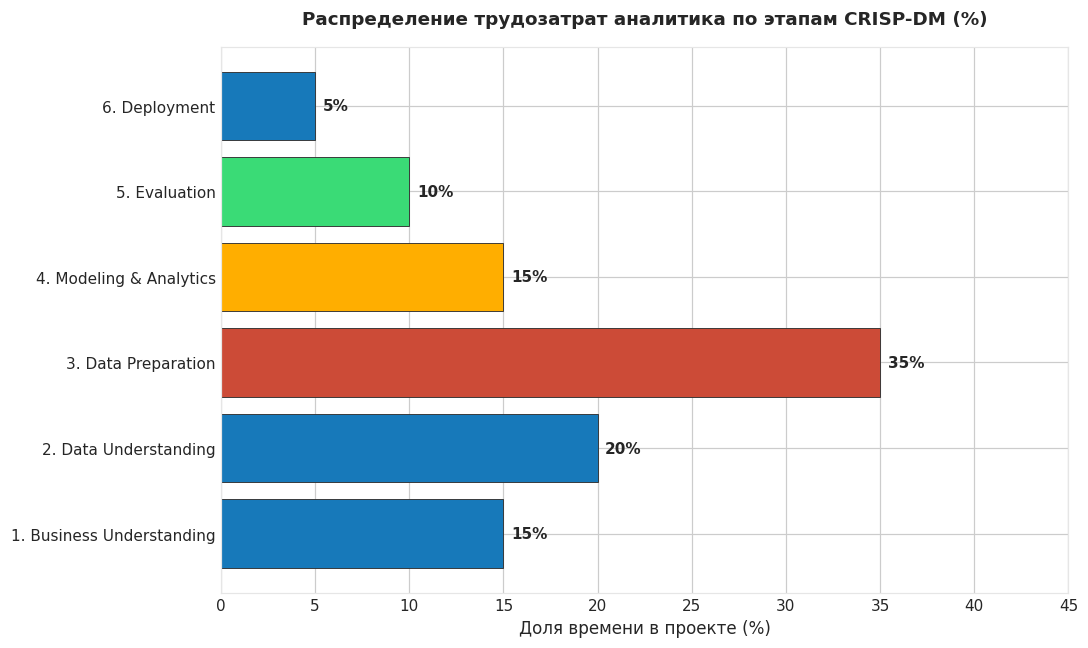

In [3]:
# Визуализация циклического процесса CRISP-DM
fig, ax = plt.subplots(figsize=(10, 6), dpi=110)

colors_crisp = [PRIMARY, PRIMARY, ALERT, WARNING, SUCCESS, PRIMARY]
bars = ax.barh(crisp_phases['Фаза CRISP-DM'], crisp_phases['Доля времени (%)'], 
               color=colors_crisp, edgecolor='#333333', linewidth=0.6)

ax.set_title("Распределение трудозатрат аналитика по этапам CRISP-DM (%)", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Доля времени в проекте (%)", fontsize=11)
ax.set_xlim(0, 45)

for b in bars:
    w = b.get_width()
    ax.annotate(f"{w}%", xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Доля работы с данными (Data Prep + Understanding)
Посчитайте совокупную долю времени, приходящуюся на этапы разведки и подготовки данных.

In [4]:
### ВАШ КОД ЗДЕСЬ
data_work_share = crisp_phases.loc[crisp_phases['Фаза CRISP-DM'].isin(['2. Data Understanding', '3. Data Preparation']), 'Доля времени (%)'].sum()
print(f"Совокупная доля работы с данными: {data_work_share}%")

assert data_work_share >= 50, "Работа с данными должна занимать не менее 50% времени"
print("✅ Тест успешно пройден: правило '80% времени уходит на данные' подтверждено!")

Совокупная доля работы с данными: 55%
✅ Тест успешно пройден: правило '80% времени уходит на данные' подтверждено!


### 💡 Золотое правило CRISP-DM
Никогда не переходите к этапу моделирования, пока не согласованы критерии успеха на этапе Business Understanding. Если стейкхолдер не знает, как измерить успех, проект обречен.